# Sesión 4 — Taller práctico

**Grupo:** 9  
**Nombre:** Mario Daniel Enrique Perez Jimenez  
**Cédula:** 1152456361  
**Código de estudiante:** 202610093727  

---

Sesión 4 — Taller práctico: del hallazgo a la decisión (CONECTA, proyecto A: Retención)

**Curso:** Visualización de Datos y Gerencia de la Información  
**Sesión:** 4 de 9  
**Tipo:** Notebook práctico

## Instrucciones de entrega

- Equipos de 3 personas. Entreguen este notebook **ejecutado de inicio a fin** como
  `DATAVIZ_sesion_4_proyecto_A_grupo_Y.ipynb` en el plazo acordado en clase.
- Completen las celdas `# TODO` y escriban en las celdas **Su respuesta**.
- Pueden consultar el notebook guiado, pero escriban su propio código. Pueden apoyarse en un asistente de IA para
  concentrarse en lo importante y en las decisiones; declaren al final para qué lo usaron.


## Problemática de negocio

CONECTA S.A. es un operador de telecomunicaciones en Bogotá con dos líneas, **Hogar** (internet fijo) y **Móvil**
(pospago y prepago), con datos sintéticos del curso. En diciembre, el comité directivo reparte el presupuesto del
primer trimestre de 2027 entre las propuestas de las gerencias. La **Gerencia de Retención** quiere una campaña para
reducir las cancelaciones. Como analistas, deben:

1. Partir del hallazgo candidato de la S3: las diez UPZ con más pérdida (el 10 % peor entre las UPZ con al menos 80
   clientes).
2. Verificar si resiste la pregunta del comité: «¿no será que tienen más clientes móviles prepago?».
3. Encontrar en qué segmento está el problema y qué lo explica (y qué no).
4. Decir cuánto vale actuar, en pesos y con un escenario declarado.
5. Construir el gráfico principal para el comité y recomendar dónde y para quién hacer la campaña, y cuánto puede
   costar como máximo.

La Tarea 3 es propia de CONECTA (Golden State no tiene segmentos): la presentación la explica en el bloque del taller.
La carpeta `datos/` no se modifica.

## Preparación del entorno

In [1]:
import pathlib
import textwrap

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# El notebook busca datos/ e imagenes/ en su carpeta (o en la de arriba, si está en solucionario/).
BASE = pathlib.Path(".") if pathlib.Path("datos").exists() else pathlib.Path("..")
DATOS, IMAGENES = BASE / "datos", BASE / "imagenes"
IMAGENES.mkdir(exist_ok=True)
# Lo que produce el taller se guarda en salidas/, junto al notebook que se ejecuta (el del estudiante en su carpeta;
# el del solucionario, en solucionario/salidas/): así el solucionario no deja respuestas en la carpeta del estudiante.
SALIDAS = pathlib.Path("salidas")
SALIDAS.mkdir(exist_ok=True)

PALETA = {"principal": "#0F766E", "principal_claro": "#4E9F96", "marino": "#1F2A44", "secundario": "#5B6475",
          "neutro": "#8A93A3", "fondo": "#F3F5F9", "acento": "#B85C0A", "texto": "#1F2937"}
plt.rcParams.update({
    "font.family": "Calibri", "font.size": 11, "axes.edgecolor": PALETA["secundario"],
    "axes.labelcolor": PALETA["texto"], "xtick.color": PALETA["secundario"], "ytick.color": PALETA["secundario"],
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 150, "savefig.dpi": 150,
    "savefig.bbox": "tight"})
# Con Calibri, matplotlib no dibuja bien los tamaños enteros 8 y 9 (se usan 8.5, 9.5 o más) ni el texto a 110 ppp: figure.dpi = 150.


def miles(n, redondeo=0):
    """Entero con espacio de miles; redondeo=-3 redondea a miles."""
    return f"{round(n, redondeo):,.0f}".replace(",", " ")


def decimal(x, d=1):
    return f"{x:.{d}f}".replace(".", ",")


def titulo(fig, texto, subtitulo, y=1.04):
    fig.text(0.01, y, texto, fontsize=15, fontweight="bold", color=PALETA["texto"], ha="left")
    fig.text(0.01, y - 0.055, subtitulo, fontsize=11, color=PALETA["secundario"], ha="left")


def fuente(fig, texto):
    fig.text(0.01, -0.04, texto, fontsize=8.5, color=PALETA["secundario"], ha="left")


def guardar(fig, nombre):
    """Guarda la figura en imagenes/ (la presentación usa estos archivos) y la muestra."""
    fig.savefig(IMAGENES / nombre)
    plt.show()


def limpiar_ejes(ax, x=True, y=False):
    if x:
        ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    if y:
        ax.set_yticks([])
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

In [2]:
FUENTE_CONECTA = "Fuente: CONECTA S.A., datos sintéticos del curso (nov. 2025 – oct. 2026). Cálculos del curso."
# Tabla limpia que dejó la S3: el «cambio de plan» ya no cuenta como pérdida (columna perdida).
d = pd.read_csv(DATOS / "conecta_limpio_s3.csv", dtype={"mes": str})
d["segmento"] = np.where(d["linea"] == "Hogar", "Hogar", np.where(d["modalidad"] == "Prepago", "Móvil prepago", "Móvil pospago"))
upz = gpd.read_file(DATOS / "upz.geojson")
MIN_CLIENTES, PEOR, UMBRAL, ESCENARIOS = 80, 0.10, 1.5, (0.25, 0.50)
print(f"{miles(d['cliente_id'].nunique())} clientes; {miles(len(d))} filas cliente-mes; pérdida mensual de Bogotá: "
      f"{decimal(100 * d['perdida'].mean(), 2)} %")
display((100 * d.groupby("segmento")["perdida"].mean()).round(2).to_frame("pérdida mensual (%)"))

36 450 clientes; 351 127 filas cliente-mes; pérdida mensual de Bogotá: 2,40 %


,pérdida mensual (%)
segmento,
Hogar,1.55
Móvil pospago,1.69
Móvil prepago,3.72


## Tarea 1 — Del hallazgo candidato a la idea central

La S3 (Tarea 5) entregó **diez UPZ candidatas**: entre las UPZ con al menos `MIN_CLIENTES` clientes, el 10 % con la
tasa de pérdida más alta. La celda siguiente **ya está hecha**: rehace esa tabla con la misma regla, porque la
verificación necesita sus columnas (`clientes`, `cliente_mes`, `perdidas`, `pct_prepago`, `tasa_pct`, `candidata`).
En esta tarea solo se lee la tabla para escribir la primera idea central.

In [3]:
# Ya está hecha: las candidatas de la S3 (la regla de la S3, Tarea 5).
por_upz = d.groupby("codigo_upz").agg(upz=("upz", "first"), localidad=("localidad", "first"),
                                    clientes=("cliente_id", "nunique"), cliente_mes=("perdida", "size"),
                                    perdidas=("perdida", "sum"),
                                    pct_prepago=("modalidad", lambda s: 100 * (s == "Prepago").mean()))
por_upz["tasa_pct"] = 100 * por_upz["perdidas"] / por_upz["cliente_mes"]
por_upz = por_upz[por_upz["clientes"] >= MIN_CLIENTES].copy()
k = round(PEOR * len(por_upz))
por_upz["candidata"] = por_upz.index.isin(por_upz.nlargest(k, "tasa_pct").index)
display(por_upz[por_upz["candidata"]].sort_values("tasa_pct", ascending=False).round(2))
veces = por_upz.loc[por_upz["candidata"], "tasa_pct"] / (100 * d["perdida"].mean())
print(f"{k} candidatas; pierden entre {decimal(veces.min(), 1)} y {decimal(veces.max(), 1)} veces la tasa de Bogotá")
print(f"El prepago es el {decimal(100 * (d['modalidad'] == 'Prepago').mean(), 1)} % de las filas de Bogotá")

,upz,localidad,clientes,cliente_mes,perdidas,pct_prepago,tasa_pct,candidata
codigo_upz,,,,,,,,
44,AMERICAS,KENNEDY,343,3028,137,38.24,4.52,True
47,KENNEDY CENTRAL,KENNEDY,423,3715,150,28.78,4.04,True
26,LAS FERIAS,ENGATIVA,524,4755,191,27.42,4.02,True
31,SANTA CECILIA,ENGATIVA,403,3678,140,30.40,3.81,True
113,BAVARIA,KENNEDY,274,2573,94,30.74,3.65,True
19,EL PRADO,SUBA,563,5170,188,24.87,3.64,True
51,LOS LIBERTADORES,SAN CRISTOBAL,177,1710,56,68.83,3.27,True
50,LA GLORIA,SAN CRISTOBAL,181,1689,55,60.45,3.26,True
84,BOSA OCCIDENTAL,BOSA,490,4590,149,72.40,3.25,True


10 candidatas; pierden entre 1,3 y 1,9 veces la tasa de Bogotá
El prepago es el 38,3 % de las filas de Bogotá


**Escriban la primera idea central en una oración (para quién, qué decisión y qué hallazgo) y la pregunta que haría el comité al ver la columna pct_prepago.**

*Consulten en la presentación:* diapositiva 10, «Análisis exploratorio frente a explicativo» (sección «Del hallazgo a la idea central»); diapositiva 12, «Quién, qué y cómo; la idea central» (sección «Del hallazgo a la idea central»).

**Su respuesta:**

- **Idea central:** para la Gerencia de Retención, que decide cómo repartir el presupuesto del primer trimestre de 2027 ante el comité de diciembre — concentrar la campaña antipérdida en las diez UPZ del 10 % peor (Américas, Kennedy Central, Las Ferias, Santa Cecilia, Bavaria, El Prado, Los Libertadores, La Gloria, Bosa Occidental y Sosiego), que pierden entre 1,3 y 1,9 veces la tasa de Bogotá (3,19 % a 4,52 % mensual frente a 2,40 %).
- **La pregunta del comité al ver `pct_prepago`:** «¿no será que pierden más simplemente porque allí hay más clientes móviles de prepago, que en toda Bogotá se van más?» La columna sugiere la sospecha: las cuatro últimas tienen 60–72 % de filas de prepago frente a 38,3 % en Bogotá, mientras las seis primeras están por debajo (25–38 %).


## Tarea 2 — Verificar contra comparables

Los comparables de cada cliente son los de **su mismo segmento** (Hogar, Móvil pospago o Móvil prepago) en toda
Bogotá: la tabla de la preparación muestra que el móvil prepago pierde mucho más que los otros dos. Las **pérdidas
esperadas** de una UPZ son las que tendría si cada cliente perdiera como su segmento en Bogotá; si la UPZ pierde
1,5 veces lo esperado o más, el exceso no se explica por su mezcla de segmentos. La presentación lo resuelve a mano
con una UPZ que no es candidata.

1. Calculen, fila por fila, la columna `esperada` (la tasa de pérdida de su segmento).
2. Por UPZ: `esperadas = suma de esperada`, `razon = perdidas / esperadas` y `exceso = perdidas - esperadas`.
3. Una candidata se **confirma** si `razon >= UMBRAL`. Repitan con 1,3 y 1,7 (robustez: como el 4 % y el 6 % de
   Golden State).
4. Hagan el gráfico de respaldo: pérdida observada frente a esperada en las diez candidatas.

In [4]:
# TODO: calculen esperada por fila, las columnas por UPZ y la columna confirmada.
# d["esperada"] = d.groupby("segmento")["perdida"].transform("mean")
# por_upz["esperadas"] = ...; por_upz["razon"] = ...; por_upz["exceso"] = ...
# por_upz["confirmada"] = ...
# Su código aquí:
d["esperada"] = d.groupby("segmento")["perdida"].transform("mean")
por_upz["esperadas"] = d.groupby("codigo_upz")["esperada"].sum()
por_upz["razon"] = por_upz["perdidas"] / por_upz["esperadas"]
por_upz["exceso"] = por_upz["perdidas"] - por_upz["esperadas"]
por_upz["confirmada"] = por_upz["candidata"] & (por_upz["razon"] >= UMBRAL)

candidatas = por_upz[por_upz["candidata"]].sort_values("tasa_pct", ascending=False)
display(candidatas[["upz", "localidad", "clientes", "pct_prepago", "tasa_pct", "perdidas",
                    "esperadas", "razon", "exceso", "confirmada"]].round(2))
conf = por_upz[por_upz["confirmada"]]
for u in (1.3, UMBRAL, 1.7):
    dentro = sorted(candidatas.loc[candidatas["razon"] >= u, "upz"].str.title())
    print(f"Umbral {u}: se confirman {len(dentro)} de {k} — {', '.join(dentro)}")
max_fuera = por_upz.loc[~por_upz["candidata"], "razon"].max()
upz_fuera = por_upz.loc[por_upz.loc[~por_upz["candidata"], "razon"].idxmax(), "upz"]
print(f"La mayor razón fuera de las candidatas es {max_fuera:.2f} ({upz_fuera.title()}): "
      f"la más cerca del umbral quedó {UMBRAL - max_fuera:.2f} por debajo.")


,upz,localidad,clientes,pct_prepago,tasa_pct,perdidas,esperadas,razon,exceso,confirmada
codigo_upz,,,,,,,,,,
44,AMERICAS,KENNEDY,343,38.24,4.52,137,72.64,1.89,64.36,True
47,KENNEDY CENTRAL,KENNEDY,423,28.78,4.04,150,81.52,1.84,68.48,True
26,LAS FERIAS,ENGATIVA,524,27.42,4.02,191,103.06,1.85,87.94,True
31,SANTA CECILIA,ENGATIVA,403,30.40,3.81,140,82.06,1.71,57.94,True
113,BAVARIA,KENNEDY,274,30.74,3.65,94,57.64,1.63,36.36,True
19,EL PRADO,SUBA,563,24.87,3.64,188,109.30,1.72,78.70,True
51,LOS LIBERTADORES,SAN CRISTOBAL,177,68.83,3.27,56,52.32,1.07,3.68,False
50,LA GLORIA,SAN CRISTOBAL,181,60.45,3.26,55,48.68,1.13,6.32,False
84,BOSA OCCIDENTAL,BOSA,490,72.40,3.25,149,144.05,1.03,4.95,False


Umbral 1.3: se confirman 6 de 10 — Americas, Bavaria, El Prado, Kennedy Central, Las Ferias, Santa Cecilia
Umbral 1.5: se confirman 6 de 10 — Americas, Bavaria, El Prado, Kennedy Central, Las Ferias, Santa Cecilia
Umbral 1.7: se confirman 5 de 10 — Americas, El Prado, Kennedy Central, Las Ferias, Santa Cecilia
La mayor razón fuera de las candidatas es 1.40 (Chapinero): la más cerca del umbral quedó 0.10 por debajo.


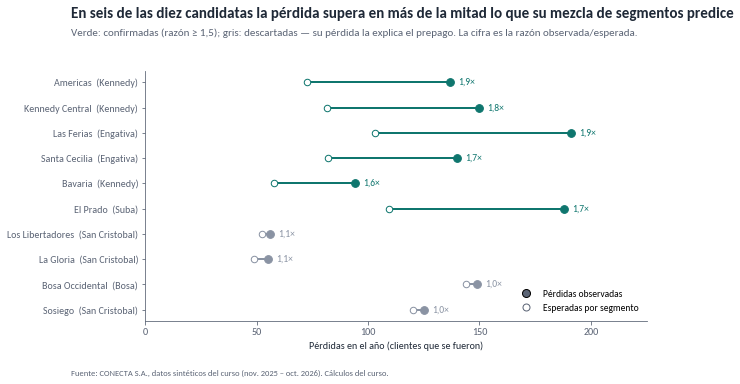

In [5]:
# TODO: hagan el gráfico de respaldo (observada frente a esperada) con un título que diga la conclusión.
# fig, ax = plt.subplots(figsize=(9, 4.6))
# Su código aquí:
fig, ax = plt.subplots(figsize=(9, 4.6))
c = candidatas.sort_values("tasa_pct")
y = range(len(c))
for i, (_, f_) in enumerate(c.iterrows()):
    color = PALETA["principal"] if f_["confirmada"] else PALETA["neutro"]
    ax.plot([f_["esperadas"], f_["perdidas"]], [i, i], color=color, linewidth=2, zorder=2)
    ax.scatter([f_["perdidas"]], [i], s=60, color=color, zorder=3)
    ax.scatter([f_["esperadas"]], [i], s=42, facecolor="white", edgecolor=color, zorder=3)
    ax.annotate(f"{decimal(f_['razon'], 1)}×", (f_["perdidas"], i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9.5, color=color)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker="o", color="none", markerfacecolor=PALETA["secundario"],
                         markersize=8, label="Pérdidas observadas"),
                   Line2D([], [], marker="o", color="none", markerfacecolor="white",
                          markeredgecolor=PALETA["secundario"], markersize=7,
                          label="Esperadas por segmento")],
          loc="lower right", fontsize=9.5, frameon=False)
ax.set_yticks(list(y)); ax.set_yticklabels([f"{u_}  ({l_})" for u_, l_ in zip(c["upz"].str.title(), c["localidad"].str.title())])
ax.set_xlabel("Pérdidas en el año (clientes que se fueron)")
ax.set_xlim(0, c["perdidas"].max() * 1.18)
titulo(fig, "En seis de las diez candidatas la pérdida supera en más de la mitad lo que su mezcla de segmentos predice",
       "Verde: confirmadas (razón ≥ 1,5); gris: descartadas — su pérdida la explica el prepago. La cifra es la razón observada/esperada.")
fuente(fig, FUENTE_CONECTA)
guardar(fig, "verificacion_candidatas.png")


**¿Cuántas candidatas se confirman, cuáles se descartan y por qué? ¿Cambia con el umbral?**

*Consulten en la presentación:* diapositiva 49, «Cómo se verifica en CONECTA» (sección «El taller: CONECTA»); diapositiva 48, «Los segmentos de clientes» (sección «El taller: CONECTA»).

**Su respuesta:**

- **Se confirman 6 de las 10 candidatas** (razón ≥ 1,5): Américas (1,89), Las Ferias (1,85), Kennedy Central (1,84), El Prado (1,72), Santa Cecilia (1,71) y Bavaria (1,63). Son UPZ de Kennedy, Engativá y Suba con 25–38 % de clientes de prepago.
- **Se descartan las otras 4**: Los Libertadores (1,07), Sosiego (1,04), Bosa Occidental (1,03) y La Gloria (1,13) — las de San Cristóbal y Bosa. Su razón ≈ 1 significa que pierden casi exactamente lo que su mezcla de segmentos predice: con 60–72 % de filas de prepago (que pierde 3,72 % al mes en Bogotá), su tasa alta era la mezcla, no la zona. Eran justamente las tres que entraron al top 10 al limpiar los datos en la S3 más La Gloria.
- **¿Cambia con el umbral?** Con 1,3 se confirman las mismas 6; con 1,7 sale Bavaria (1,63) y quedan 5. El resultado es robusto para la campaña: el grupo dudoso es de una sola UPZ.


## Tarea 3 — ¿En qué segmento está el problema y qué lo explica?

Antes de valorar la campaña hay que saber **a quién** va dirigida y **por qué** se van esos clientes.

1. **Dónde:** en las UPZ confirmadas y en el resto de Bogotá, calculen la razón observada/esperada **por segmento**
   (`razon_segmento`).
2. **Qué lo acompaña:** solo para los clientes de **Hogar**, comparen las confirmadas con el resto en quejas por mes,
   uso de datos (mediana), lo que pagan, porcentaje de pérdidas con menos de seis meses de antigüedad (la medida
   de la S2), NPS medio, porcentaje de pérdidas voluntarias y tasa de pérdida
   antes y desde agosto de 2026 (`mecanismo`).

In [6]:
# TODO: calculen razon_segmento y la tabla mecanismo (solo Hogar).
# conf = por_upz[por_upz["confirmada"]]
# grupo = d["codigo_upz"].isin(conf.index).map({True: "UPZ confirmadas", False: "Resto de Bogotá"})
# t = d.groupby([grupo, "segmento"]).agg(perdidas=("perdida", "sum"), esperadas=("esperada", "sum"))
# razon_segmento = (t["perdidas"] / t["esperadas"]).unstack()
# h = d[d["segmento"] == "Hogar"]; gh = grupo.loc[h.index]
# mecanismo = pd.DataFrame({"quejas_mes": h.groupby(gh)["quejas_mes"].mean(), ...}).T
# Su código aquí:
grupo = d["codigo_upz"].isin(conf.index).map({True: "UPZ confirmadas", False: "Resto de Bogotá"})
t = d.groupby([grupo, "segmento"]).agg(perdidas=("perdida", "sum"), esperadas=("esperada", "sum"))
razon_segmento = (t["perdidas"] / t["esperadas"]).unstack()
display(razon_segmento.round(2))

h = d[d["segmento"] == "Hogar"]
gh = grupo.loc[h.index]
hp = h[h["perdida"] == 1]
mecanismo = pd.DataFrame({
    "quejas por mes (media)": h.groupby(gh)["quejas_mes"].mean(),
    "uso de datos, GB (mediana)": h.groupby(gh)["uso_datos_gb"].median(),
    "ingreso mensual, COP (media)": h.groupby(gh)["ingreso_mensual_cop"].mean(),
    "pérdidas con < 6 meses de antigüedad (%)":
        100 * (hp["antiguedad_meses"] < 6).groupby(gh.loc[hp.index]).mean(),
    "NPS medio": h.groupby(gh)["nps"].mean(),
    "pérdidas voluntarias (%)":
        100 * (hp["tipo_cancelacion"] == "Voluntaria").groupby(gh.loc[hp.index]).mean(),
    "tasa de pérdida nov 2025–jul 2026 (%)":
        100 * h[h["mes"] < "2026-08"].groupby(gh.loc[h[h["mes"] < "2026-08"].index])["perdida"].mean(),
    "tasa de pérdida ago–oct 2026 (%)":
        100 * h[h["mes"] >= "2026-08"].groupby(gh.loc[h[h["mes"] >= "2026-08"].index])["perdida"].mean(),
}).T
display(mecanismo.round(2))
responde = 100 * h.groupby(gh)["nps"].apply(lambda s: s.notna().mean())
print(f"Responden la encuesta de NPS: {decimal(responde['UPZ confirmadas'], 1)} % de las filas de Hogar en las "
      f"confirmadas y {decimal(responde['Resto de Bogotá'], 1)} % en el resto.")
ing = h.groupby(gh)["ingreso_mensual_cop"].mean()
print(f"Diferencia de ingreso mensual de Hogar: +{decimal(100 * (ing['UPZ confirmadas'] / ing['Resto de Bogotá'] - 1), 1)} %")


segmento,Hogar,Móvil pospago,Móvil prepago
codigo_upz,,,
Resto de Bogotá,0.84,1.00,1.00
UPZ confirmadas,3.02,0.98,1.03


codigo_upz,Resto de Bogotá,UPZ confirmadas
quejas por mes (media),0.19,0.17
"uso de datos, GB (mediana)",258.50,265.35
"ingreso mensual, COP (media)",85694.66,87702.53
pérdidas con < 6 meses de antigüedad (%),15.65,14.68
NPS medio,8.12,6.79
pérdidas voluntarias (%),70.94,86.53
tasa de pérdida nov 2025–jul 2026 (%),1.29,4.35
tasa de pérdida ago–oct 2026 (%),1.33,5.83


Responden la encuesta de NPS: 18,3 % de las filas de Hogar en las confirmadas y 21,5 % en el resto.
Diferencia de ingreso mensual de Hogar: +2,3 %


**¿En qué segmento está el exceso? ¿Qué lo explica y qué explicaciones quedan descartadas?**

*Consulten en la presentación:* diapositiva 50, «Tarea 3 en CONECTA» (sección «El taller: CONECTA»); diapositiva 31, «Lista de verificación previa al comité» (sección «Cuánto vale y el SCQA»).

**Su respuesta:**

- **El exceso está todo en Hogar**: en las UPZ confirmadas los clientes de Hogar pierden **3,02 veces** lo que su segmento predice en Bogotá, mientras el pospago (0,98) y el prepago (1,03) pierden justo lo esperado. En el resto de Bogotá el pospago y el prepago rondan 1,0 y Hogar queda en 0,84. La campaña es para los clientes de Hogar.
- **Lo que lo acompaña (los indicadores que sí señalan):** NPS medio más bajo (6,8 frente a 8,1 — aunque solo responde el 18 %), más pérdidas **voluntarias** (86,5 % frente a 70,9 %) y una tasa que **queda más alta desde agosto** (promedio 4,4 % → 5,8 % frente a ~1,3 % del resto — con tres meses es una señal, no una tendencia).
- **Descartadas:** la **red** — las quejas por mes son iguales o menores (0,17 frente a 0,19) y la mediana de uso de datos es casi igual (265 frente a 259 GB); el **precio** — pagan apenas un 2,3 % más (87 703 frente a 85 695 COP); y **clientes nuevos** — la proporción de pérdidas con menos de seis meses es la misma (14,7 % frente a 15,7 %).


## Tarea 4 — Cuánto vale y el SCQA

La campaña va para los clientes de **Hogar** de las UPZ confirmadas (Tarea 3).

1. **Magnitud:** exceso de pérdidas de Hogar en el año (`exceso` = pérdidas − esperadas, solo filas de Hogar de las
   confirmadas), ARPU de esos clientes, ingreso anual que se va (`exceso × ARPU × 12`) y ganancia de la campaña en
   cada escenario (`× fracción recuperada`).
   - **ARPU** (ingreso medio por cliente y mes, definición del curso): el promedio de `ingreso_mensual_cop` en las
     filas cliente-mes de Hogar de las UPZ confirmadas. Se promedia por fila: cada mes de cada cliente pesa lo mismo.
   - **Fracción recuperada:** una cuarta parte (escenario prudente) y la mitad. Es un supuesto del caso, no un dato:
     los datos no dicen cuántos clientes recuperaría la campaña. Por eso se muestran dos escenarios.
2. **Costo máximo por cliente:** ganancia en el escenario prudente / clientes activos. **Clientes activos:** los
   `cliente_id` de Hogar distintos que tienen fila en el último mes de la tabla (`d["mes"].max()`, octubre de 2026)
   en las UPZ confirmadas.
3. **Estabilidad (robustez por periodo):** tasa mensual de los clientes de Hogar de las confirmadas frente a los del
   resto de Bogotá (gráfico de líneas). Es la evidencia para la robustez por periodo de la lista de verificación.

*Consulten en la presentación:* diapositiva 51, «El mismo razonamiento en CONECTA» (sección «El taller: CONECTA»); diapositiva 22, «Cuánto vale actuar» (sección «Cuánto vale y el SCQA»).

In [7]:
# TODO: calculen la magnitud, la ganancia por escenario y el costo máximo por cliente.
# en_conf = h[h["codigo_upz"].isin(conf.index)]          # filas de Hogar de las confirmadas
# exceso = en_conf["perdida"].sum() - en_conf["esperada"].sum(); arpu = ...
# ganancia = {f: ... for f in ESCENARIOS}; activos = ...; costo_maximo = ...
# Su código aquí:
en_conf = h[h["codigo_upz"].isin(conf.index)]
exceso = en_conf["perdida"].sum() - en_conf["esperada"].sum()
arpu = en_conf["ingreso_mensual_cop"].mean()
ingreso_anual = exceso * arpu * 12
ganancia = {f: ingreso_anual * f for f in ESCENARIOS}
activos = en_conf[en_conf["mes"] == d["mes"].max()]["cliente_id"].nunique()
costo_maximo = ganancia[ESCENARIOS[0]] / activos
print(f"Exceso de pérdidas de Hogar en el año: {decimal(exceso, 1)} clientes (de {miles(en_conf['perdida'].sum())} "
      f"observadas frente a {decimal(en_conf['esperada'].sum(), 0)} esperadas)")
print(f"ARPU de Hogar en las confirmadas: COP {miles(arpu)} por mes; ingreso anual que se va: "
      f"COP {decimal(ingreso_anual / 1e6, 0)} millones")
for f_, g_ in ganancia.items():
    print(f"Ganancia si la campaña recupera el {int(100 * f_)} % del exceso: COP {decimal(g_ / 1e6, 1)} millones al año")
print(f"Clientes activos de Hogar en octubre de 2026 en las confirmadas: {miles(activos)}")
print(f"Costo máximo por cliente (escenario prudente / activos): COP {miles(costo_maximo)}")
print("«Ganancia» es el ingreso recuperado antes de costos de la campaña; el horizonte es anual, "
      "como pide el taller — el presupuesto que se decide es del trimestre y usa el mismo supuesto.")


# Contrafactual de la Pregunta 1: el mismo flujo con `cancelo` (sin la limpieza de la S3).
esperada_c = d.groupby("segmento")["cancelo"].transform("mean")
por_upz["esperadas_c"] = esperada_c.groupby(d["codigo_upz"]).sum()
por_upz["perdidas_c"] = d.groupby("codigo_upz")["cancelo"].sum()
por_upz["razon_c"] = por_upz["perdidas_c"] / por_upz["esperadas_c"]
conf_c = por_upz[por_upz["candidata"] & (por_upz["razon_c"] >= UMBRAL)]
print(f"Contrafactual con `cancelo`: se confirmarían {len(conf_c)} UPZ — "
      f"{', '.join(sorted(conf_c['upz'].str.title()))}")
raz_bavaria = por_upz.loc[por_upz["upz"].str.upper() == "BAVARIA", "razon_c"].iloc[0]
print(f"Bavaria quedaría con razón {decimal(raz_bavaria, 2)} (< {UMBRAL}): una UPZ con problema real queda fuera")
en_conf_c = h[h["codigo_upz"].isin(conf_c.index)]
exc_c = en_conf_c["cancelo"].sum() - esperada_c.loc[en_conf_c.index].sum()
arpu_c = en_conf_c["ingreso_mensual_cop"].mean()
print(f"Exceso con `cancelo`: {decimal(exc_c, 1)} clientes ≈ COP {decimal(exc_c * arpu_c * 12 / 1e6, 1)} M "
      f"(con `perdida`: {decimal(exceso, 1)} ≈ COP {decimal(ingreso_anual / 1e6, 0)} M)")
exc_c6 = en_conf["cancelo"].sum() - esperada_c.loc[en_conf.index].sum()
print(f"Sobre las mismas 6 UPZ, exceso con `cancelo`: {decimal(exc_c6, 1)} ≈ COP "
      f"{decimal(exc_c6 * arpu * 12 / 1e6, 1)} M — la magnitud no se infla, queda igual o menor")
print(f"La pérdida esperada de Hogar sube de {decimal(100 * h['perdida'].mean(), 2)} % a "
      f"{decimal(100 * h['cancelo'].mean(), 2)} %")

# El ranking con `cancelo` (mismo método de la S3: ≥80 clientes únicos por UPZ, k = 10 %).
rank = (d.groupby(["codigo_upz", "upz"])
        .agg(clientes=("cliente_id", "nunique"), tasa_c=("cancelo", "mean"), tasa_p=("perdida", "mean")))
rank = rank[rank["clientes"] >= 80]
top_p = set(rank["tasa_p"].nlargest(round(0.10 * len(rank))).index.get_level_values("upz"))
top_c = set(rank["tasa_c"].nlargest(round(0.10 * len(rank))).index.get_level_values("upz"))
print(f"Top 10 con «cancelo»: habrían entrado {', '.join(u.title() for u in sorted(top_c - top_p))} "
      f"en lugar de {', '.join(u.title() for u in sorted(top_p - top_c))}")

# El «cambio de plan» (Pregunta 1): segmento y estrato de las filas afectadas.
cp = d[d["tipo_cancelacion"] == "Cambio de plan"]
seg_cp = cp.groupby("segmento").size() / len(cp)
est_cp = cp.groupby("estrato").size() / len(cp)
print("«Cambio de plan» por segmento: " + ", ".join(f"{s_.title()} {100 * v_:.1f} %" for s_, v_ in seg_cp.items()))
print("«Cambio de plan» por estrato: " + ", ".join(f"{int(e_)}: {100 * v_:.1f} %" for e_, v_ in est_cp.items())
      + f" — estratos 2–3 suman {100 * est_cp.loc[[2, 3]].sum():.1f} % y 4–6, {100 * est_cp.loc[[4, 5, 6]].sum():.1f} %")

# Sensibilidad de la línea base: la esperada usa toda Bogotá; con solo el «resto» la conclusión se fortalece.
esp_resto = h[~h["codigo_upz"].isin(conf.index)]["perdida"].mean()
exc_alt = en_conf["perdida"].sum() - len(en_conf) * esp_resto
print(f"Sensibilidad: esperada de Hogar calculada solo con el resto de Bogotá = {decimal(100 * esp_resto, 2)} %; "
      f"el exceso sube a {decimal(exc_alt, 1)} y la razón a {decimal(en_conf['perdida'].mean() / esp_resto, 2)}×: "
      "la conclusión se fortalece, no cambia.")

Exceso de pérdidas de Hogar en el año: 387,5 clientes (de 579 observadas frente a 192 esperadas)
ARPU de Hogar en las confirmadas: COP 87 703 por mes; ingreso anual que se va: COP 408 millones
Ganancia si la campaña recupera el 25 % del exceso: COP 102,0 millones al año
Ganancia si la campaña recupera el 50 % del exceso: COP 203,9 millones al año
Clientes activos de Hogar en octubre de 2026 en las confirmadas: 878
Costo máximo por cliente (escenario prudente / activos): COP 116 121
«Ganancia» es el ingreso recuperado antes de costos de la campaña; el horizonte es anual, como pide el taller — el presupuesto que se decide es del trimestre y usa el mismo supuesto.
Contrafactual con `cancelo`: se confirmarían 5 UPZ — Americas, El Prado, Kennedy Central, Las Ferias, Santa Cecilia
Bavaria quedaría con razón 1,36 (< 1.5): una UPZ con problema real queda fuera
Exceso con `cancelo`: 350,9 clientes ≈ COP 369,5 M (con `perdida`: 387,5 ≈ COP 408 M)
Sobre las mismas 6 UPZ, exceso con `cancelo`: 382

codigo_upz,Resto de Bogotá,UPZ confirmadas
mes,,
2025-11,1.16,4.00
2025-12,1.27,4.10
2026-01,1.37,3.84
2026-02,1.25,4.90
2026-03,1.42,4.57
2026-04,1.28,3.71
2026-05,1.27,4.85
2026-06,1.24,4.81
2026-07,1.35,4.44


mes
2025-11    3.46
2025-12    3.23
2026-01    2.80
2026-02    3.90
2026-03    3.22
2026-04    2.89
2026-05    3.81
2026-06    3.88
2026-07    3.30
2026-08    4.78
2026-09    4.33
2026-10    4.08
Name: razon confirmadas/resto, dtype: float64

La razón mensual va de 2,8× a 4,8× (mínima en 2026-01, máxima en 2026-08)


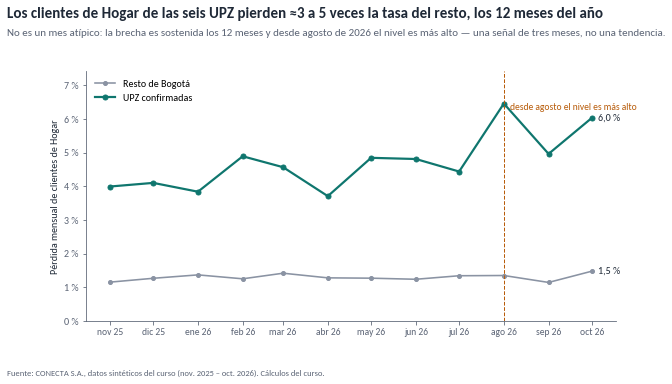

In [8]:
# TODO: hagan la serie mensual de los clientes de Hogar: confirmadas frente al resto de Bogotá.
# serie = 100 * h.groupby(["mes", gh])["perdida"].mean().unstack()     # h y gh vienen de la Tarea 3
# Su código aquí:
serie = 100 * h.groupby(["mes", gh])["perdida"].mean().unstack()
display(serie.round(2))
razon_mes = serie["UPZ confirmadas"] / serie["Resto de Bogotá"]
display(razon_mes.round(2).rename("razon confirmadas/resto"))
print(f"La razón mensual va de {decimal(razon_mes.min(), 1)}× a {decimal(razon_mes.max(), 1)}× "
      f"(mínima en {razon_mes.idxmin()}, máxima en {razon_mes.idxmax()})")
fig, ax = plt.subplots(figsize=(9.5, 4.6))
meses = pd.to_datetime(serie.index, format="%Y-%m")
ax.plot(meses, serie["Resto de Bogotá"], color=PALETA["neutro"], linewidth=1.6, marker="o", markersize=4,
        label="Resto de Bogotá")
ax.plot(meses, serie["UPZ confirmadas"], color=PALETA["principal"], linewidth=2.2, marker="o", markersize=5,
        label="UPZ confirmadas")
ax.axvline(pd.Timestamp("2026-08"), color=PALETA["acento"], linewidth=1, linestyle="--")
ax.annotate("desde agosto el nivel es más alto", (pd.Timestamp("2026-08"), serie["UPZ confirmadas"].max() * 0.97),
            xytext=(6, 0), textcoords="offset points", fontsize=9.5, color=PALETA["acento"])
for x_, y_, v_ in ((meses[-1], serie["UPZ confirmadas"].iloc[-1], serie["UPZ confirmadas"].iloc[-1]),
                 (meses[-1], serie["Resto de Bogotá"].iloc[-1], serie["Resto de Bogotá"].iloc[-1])):
    ax.annotate(f"{decimal(v_, 1)} %", (x_, y_), xytext=(6, 0), textcoords="offset points", fontsize=10,
                color=PALETA["texto"], va="center")
ax.set_ylim(0, serie["UPZ confirmadas"].max() * 1.15)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f} %")
ROTULOS_MES = {"2025-11": "nov 25", "2025-12": "dic 25", "2026-01": "ene 26", "2026-02": "feb 26",
               "2026-03": "mar 26", "2026-04": "abr 26", "2026-05": "may 26", "2026-06": "jun 26",
               "2026-07": "jul 26", "2026-08": "ago 26", "2026-09": "sep 26", "2026-10": "oct 26"}
ax.set_xticks(meses); ax.set_xticklabels([ROTULOS_MES[m] for m in serie.index], fontsize=9.5)
ax.set_ylabel("Pérdida mensual de clientes de Hogar")
ax.legend(fontsize=10, frameon=False, loc="upper left")
titulo(fig, "Los clientes de Hogar de las seis UPZ pierden ≈3 a 5 veces la tasa del resto, los 12 meses del año",
       "No es un mes atípico: la brecha es sostenida los 12 meses y desde agosto de 2026 el nivel es más alto — una señal de tres meses, no una tendencia.")
fuente(fig, FUENTE_CONECTA)
guardar(fig, "serie_mensual_hogar.png")



**Escriban el SCQA para el comité (S, C, Q y A). Partan de lo que traemos de la S1 a la S3: ¿qué hallazgo se confirmó, cuál resultó ser la mezcla de segmentos y cuál no explica las zonas?**

*Consulten en la presentación:* diapositiva 28, «SCQA: el orden que necesita la audiencia» (sección «Cuánto vale y el SCQA»); diapositiva 46, «LO QUE TRAEMOS DE CONECTA» (sección «El taller: CONECTA»).

**Su respuesta:**

- **S — Situación:** la Gerencia de Retención lleva al comité de diciembre una propuesta de campaña contra las cancelaciones para el primer trimestre de 2027. En la S2 el análisis por localidad con datos crudos sugería un problema de zonas; la S3 limpió la base (duplicados, cuentas internas, y el «cambio de plan» que no es pérdida) y marcó las diez UPZ del 10 % peor.
- **C — Complicación:** la lista podría ser un espejismo de la mezcla de segmentos — el prepago pierde 3,72 % al mes en toda Bogotá y cuatro candidatas tienen 60–72 % de filas de prepago. La pregunta del comité era justamente esa: «¿no será que pierden más porque tienen más prepago?».
- **Q — Pregunta:** ¿dónde y para quién debe hacer la campaña, y cuánto puede costar como máximo?
- **A — Respuesta:** para los clientes de **Hogar** de las seis UPZ confirmadas (Américas, Kennedy Central y Bavaria en Kennedy; Las Ferias y Santa Cecilia en Engativá; El Prado en Suba): su Hogar pierde 3,0 veces lo esperado de su segmento, un exceso de ~388 clientes al año que equivalen a COP 408 millones de ingreso. Si la campaña recupera una cuarta parte del exceso gana COP ~102 millones al año, así que **no debería costar más de ~COP 116 mil por cliente activo** (878 clientes). Las cuatro candidatas de San Cristóbal y Bosa eran la mezcla de prepago — no necesitan campaña de zona.


**Lista de verificación: magnitud, mecanismo, robustez (umbral y periodo: usen la serie mensual), explicaciones alternativas y accionabilidad.**

*Consulten en la presentación:* diapositiva 31, «Lista de verificación previa al comité» (sección «Cuánto vale y el SCQA»).

**Su respuesta:**

| Criterio | Respuesta con cifras |
|---|---|
| **Magnitud** | Exceso de ~388 clientes de Hogar al año = COP 408 M de ingreso anual; la campaña del escenario prudente recupera ~COP 102 M de ingreso anual (antes de costos; ~204 M con la mitad). |
| **Mecanismo** | Coherente con insatisfacción: NPS 6,8 frente a 8,1 y 86,5 % de pérdidas voluntarias; nivel más alto desde agosto (4,4 % → 5,8 % — señal de tres meses, no tendencia). Descartados la red (quejas y uso iguales), el precio (+2,3 %) y la antigüedad (< 6 meses igual). |
| **Robustez — umbral** | Las mismas 6 UPZ se confirman con razón ≥ 1,3; con ≥ 1,7 solo sale Bavaria. |
| **Robustez — periodo** | La serie mensual muestra la brecha sostenida los 12 meses (3,7–6,5 % frente a ~1,3 %): no es un mes atípico. |
| **Explicaciones alternativas** | La mezcla de segmentos ya está controlada (razón por segmento); queda por descartar un problema de instalación o servicio que los datos no miden — revisión técnica en sitio antes de firmar. |
| **Accionabilidad** | Acción concreta: campaña de retención a los 878 clientes activos de Hogar de las 6 UPZ, con techo de gasto de ~COP 116 mil por cliente. |


## Tarea 5 — El gráfico principal y la recomendación

Primero miren el gráfico «antes»: la cancelación por localidad que habría llevado al comité un equipo que se saltara
la S3 (la celda ya está hecha). Luego construyan el gráfico de decisión: a la izquierda, el mapa de las UPZ
confirmadas, y a la derecha, un panel con la ganancia anual por localidad (escenario prudente), con un título que diga
la conclusión. **El mapa ya está hecho** (función `mapa_confirmadas`): los mapas son el tema de la S5, donde se
construyen y se discute a qué escala mirarlos. Ustedes hacen el panel, el título y la recomendación. La ganancia de cada localidad usa el ARPU de los clientes de Hogar de esa localidad (regla del curso),
así que la suma por localidad no da exactamente el total de la Tarea 4: hay que decirlo donde aparezcan las dos cifras.

**Lista de chequeo del gráfico principal** (la misma de la presentación; sirve para revisar el gráfico antes de entregarlo, no se responde por escrito):

1. ¿El título dice la conclusión y la decisión que debe tomar el comité?
2. ¿Las barras empiezan en cero?
3. ¿Un color para el mensaje y gris para el contexto?
4. ¿Etiquetas directas en lugar de ejes y leyendas?
5. ¿El escenario y la fuente están declarados?
6. ¿El mapa muestra el *dónde* y las barras el *cuánto*?

*Consulten en la presentación:* diapositiva 35, «Gráfico de decisión frente a gráfico de evidencia» (sección «El gráfico principal»); diapositiva 40, «Las seis decisiones de diseño» (sección «El gráfico principal»); diapositiva 31, «Lista de verificación previa al comité» (sección «Cuánto vale y el SCQA»).

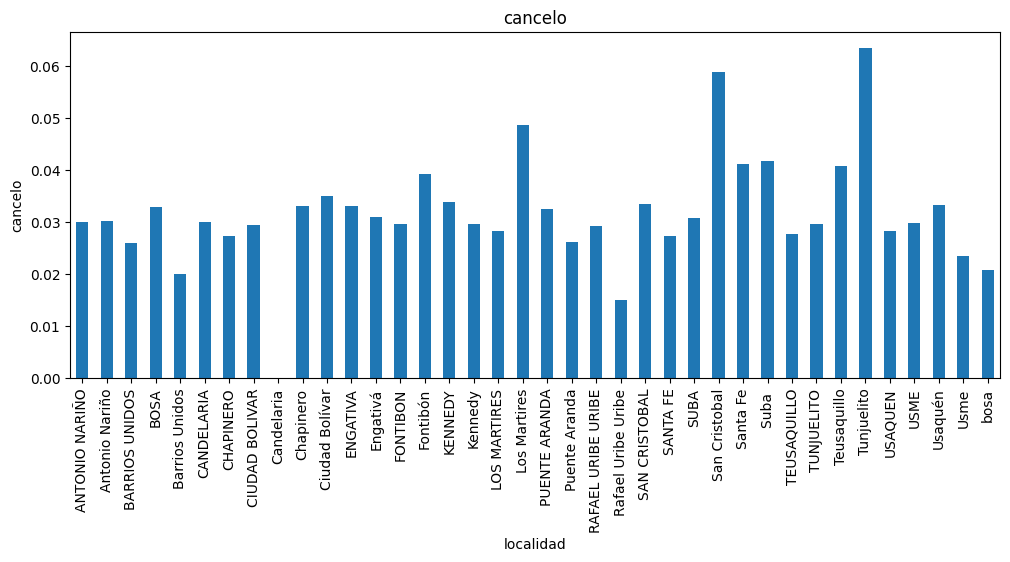

38 barras; la tabla limpia de la S3 tiene 19 localidades


In [9]:
# Gráfico «antes» (ya está hecho): los datos crudos, la columna cancelo tal cual y el estilo por defecto.
crudo = pd.read_csv(DATOS / "conecta_clientes_mes.csv", dtype={"mes": str})
antes_loc = crudo.groupby("localidad")["cancelo"].mean()
with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(12, 4.5))
    antes_loc.plot.bar(ax=ax)
    ax.set_title("cancelo")
    ax.set_ylabel("cancelo")
    plt.show()
print(f"{antes_loc.size} barras; la tabla limpia de la S3 tiene {d['localidad'].nunique()} localidades")

In [10]:
# Ya está hecha (los mapas son el tema de la S5): dibuja las UPZ con las confirmadas resaltadas y sus nombres.
def mapa_confirmadas(ax, confirmadas):
    es_conf = upz["codigo_upz"].isin(confirmadas.index)
    upz[~es_conf].plot(ax=ax, color="#D9DEE7", edgecolor="white", linewidth=0.5)
    upz[es_conf].plot(ax=ax, color=PALETA["principal"], edgecolor="white", linewidth=0.8)
    # Rótulos en una columna a la izquierda, ordenados por latitud y separados para que no se monten.
    puntos = sorted(((f.geometry.representative_point(), f["upz"].title()) for _, f in upz[es_conf].iterrows()),
                    key=lambda x: x[0].y)
    x_rotulo, y_previo = upz.total_bounds[0] + 0.02, -1e9
    for punto, nombre in puntos:
        y_rotulo = max(punto.y, y_previo + 0.018); y_previo = y_rotulo
        ax.annotate(nombre, (punto.x, punto.y), xytext=(x_rotulo, y_rotulo), textcoords="data", fontsize=9.5, ha="right",
                    va="center", arrowprops={"arrowstyle": "-", "color": PALETA["secundario"], "linewidth": 0.6})
    ax.set_axis_off()

,perdidas,esperadas,exceso,ganancia_prudente,arpu
localidad,,,,,
ENGATIVA,212,71.2,140.8,36837185.2,87222.5
KENNEDY,237,74.9,162.1,41785318.2,85941.4
SUBA,130,45.3,84.7,23203054.3,91366.5


La suma por localidad (COP 101,8 M) usa el ARPU de cada localidad; el total de la Tarea 4 (COP 102,0 M) usa el ARPU de las seis juntas: son cifras cercanas pero no idénticas.
Kennedy y Engativá concentran el 77,2 % de la ganancia prudente por localidad


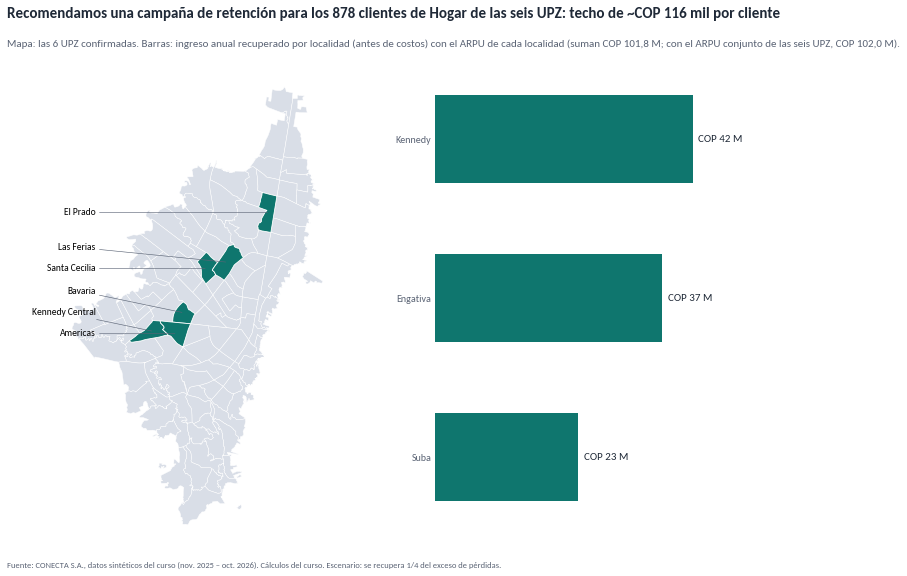

In [11]:
# TODO: calculen la ganancia por localidad y hagan el panel, el título y la composición con el mapa.
# arpu_loc = en_conf.groupby("localidad")["ingreso_mensual_cop"].mean()
# por_localidad = en_conf.groupby("localidad").agg(perdidas=("perdida", "sum"), esperadas=("esperada", "sum"))
# fig = plt.figure(figsize=(11, 7.2))
# mapa_confirmadas(fig.add_axes([0.0, 0.0, 0.5, 0.93]), conf)      # el mapa ya está hecho
# px = fig.add_axes([0.55, 0.05, 0.43, 0.86])                      # el panel de barras es suyo
# Su código aquí:
arpu_loc = en_conf.groupby("localidad")["ingreso_mensual_cop"].mean()
por_localidad = en_conf.groupby("localidad").agg(perdidas=("perdida", "sum"), esperadas=("esperada", "sum"))
por_localidad["exceso"] = por_localidad["perdidas"] - por_localidad["esperadas"]
por_localidad["ganancia_prudente"] = por_localidad["exceso"] * arpu_loc * 12 * ESCENARIOS[0]
display(por_localidad.assign(arpu=arpu_loc).round(1))
print(f"La suma por localidad (COP {decimal(por_localidad['ganancia_prudente'].sum() / 1e6, 1)} M) usa el ARPU de cada "
      f"localidad; el total de la Tarea 4 (COP {decimal(ganancia[ESCENARIOS[0]] / 1e6, 1)} M) usa el ARPU de las seis juntas: "
      "son cifras cercanas pero no idénticas.")
parte_ken_eng = por_localidad.loc[["KENNEDY", "ENGATIVA"], "ganancia_prudente"].sum() / por_localidad["ganancia_prudente"].sum()
print(f"Kennedy y Engativá concentran el {decimal(100 * parte_ken_eng, 1)} % de la ganancia prudente por localidad")

fig = plt.figure(figsize=(11, 7.2))
mapa_confirmadas(fig.add_axes([0.0, 0.0, 0.5, 0.93]), conf)      # el mapa ya está hecho
px = fig.add_axes([0.55, 0.05, 0.43, 0.86])                      # el panel de barras
p = por_localidad.sort_values("ganancia_prudente")
colores = [PALETA["principal"]] * len(p)   # las tres localidades son las recomendadas
px.barh(p.index.str.title(), p["ganancia_prudente"], color=colores, height=0.55)
for i, v_ in enumerate(p["ganancia_prudente"]):
    px.text(v_ + 900_000, i, f"COP {decimal(v_ / 1e6, 0)} M", va="center", fontsize=11, color=PALETA["texto"])
px.set_xlim(0, p["ganancia_prudente"].max() * 1.32)
limpiar_ejes(px)
titulo(fig, "Recomendamos una campaña de retención para los 878 clientes de Hogar de las seis UPZ: techo de ~COP 116 mil por cliente",
       "Mapa: las 6 UPZ confirmadas. Barras: ingreso anual recuperado por localidad (antes de costos) con el ARPU de cada localidad (suman COP 101,8 M; "
       "con el ARPU conjunto de las seis UPZ, COP 102,0 M).", y=1.02)
fuente(fig, FUENTE_CONECTA + " Escenario: se recupera 1/4 del exceso de pérdidas.")
guardar(fig, "grafico_principal_campana.png")


**Diagnostiquen el gráfico «antes» (cancelación cruda por localidad): ¿es feo, malo o erróneo? ¿Por qué?**

*Consulten en la presentación:* diapositiva 36, «Antes del gráfico principal» (sección «El gráfico principal»).

**Su respuesta:**

Es **erróneo**, no solo feo ni solo malo:

- **Erróneo en el dato**: usa `cancelo` sin la limpieza de la S3, así que cuenta el «cambio de plan» — el 22,6 % de las cancelaciones de la base limpia — como si fueran salidas; incluye las 150 cuentas internas con pago 0 y los 1 765 duplicados; y pinta 38 barras de «localidad» porque no normalizó las grafías (19 reales). La conclusión a la que llevaría está inflada.
- **Malo en la forma**: barras en orden alfabético que no ordenan el mensaje, título genérico («cancelo») que nombra la columna y no la conclusión, sin fuente, sin referencia de qué es una tasa alta y con el estilo por defecto.
- **Y no lleva a decidir**: aunque las cifras fueran correctas, un promedio por localidad no dice a quién va la campaña — las localidades mezclan los tres segmentos y el problema real es de Hogar en unas UPZ concretas.


**Escriban la recomendación con su magnitud y lo que el comité preguntará después.**

*Consulten en la presentación:* diapositiva 31, «Lista de verificación previa al comité» (sección «Cuánto vale y el SCQA»).

**Su respuesta:**

Recomendamos una **campaña de retención dirigida a los 878 clientes activos de Hogar de las seis UPZ confirmadas** (Américas, Kennedy Central y Bavaria en Kennedy; Las Ferias y Santa Cecilia en Engativá; El Prado en Suba). Magnitud: el exceso es de ~388 clientes al año, COP 408 M de ingreso anual; con el escenario prudente (recuperar una cuarta parte) la campaña recupera **~COP 102 M de ingreso al año** (antes de costos), así que el presupuesto máximo es **~COP 116 mil por cliente** (~COP 102 M en total).

Lo que el comité preguntará después:

- **¿En qué se gasta?** El dato no dice qué oferta funciona — el mecanismo apunta a insatisfacción (NPS bajo, salidas voluntarias y nivel más alto desde agosto), así que conviene una acción de retención (contacto, mejora de plan, visita técnica) más que un descuento a ciegas.
- **¿Cómo se mide el éxito?** Comparando la tasa mensual de Hogar de las confirmadas contra su esperada de segmento; la serie muestra que hoy está ≈3 a 5 veces arriba.
- **¿Por qué quedó más alta desde agosto?** Los datos no lo explican — puede ser un cambio operativo o de competencia que el comité sí conoce.
- **¿Y las otras cuatro candidatas?** Su exceso era la mezcla de prepago; si se quiere actuar allí, es una campaña de segmento prepago para toda Bogotá, no de zona.


## Preguntas de interpretación

**1. Con la columna cancelo (sin la limpieza de la S3), ¿qué habría pasado con la recomendación?**

**Su respuesta:**

Con `cancelo` (sin la limpieza de la S3) la recomendación habría cambiado en tres niveles:

1. **Otra lista de candidatas**: con `cancelo` el top 10 habría sido otro — Los Andes, El Tesoro y Chapinero seguirían dentro en lugar de Sosiego, Los Libertadores y Bosa Occidental (que solo entran cuando se limpia: el «cambio de plan» es el 22,6 % de las cancelaciones y se concentra en Hogar (el 78 % de los cambios) y pospago (22 %), sobre todo en estratos 2 y 3 (63 %)). Verificaríamos una lista distinta.
2. **La confirmación se deforma**: como el cambio de plan pesa sobre Hogar, las tasas de los segmentos no estarían limpias: la «pérdida esperada» quedaría inflada justo en el segmento donde está el problema, y la razón observada/esperada se atenuaría — alguna confirmada real podría no pasar el umbral.
3. **La campaña quedaría mal apuntada — por cobertura, no por pesos**: con `cancelo` la pérdida esperada de Hogar también se infla (de 1,55 % a 2,67 %), la razón se atenúa y **solo se confirmarían 5 UPZ** (Bavaria queda en 1,36): una zona con problema real quedaría fuera del presupuesto. Y la magnitud no se infla — queda igual o menor: ~351 clientes de exceso ≈ COP 369 M con el flujo completo, y ~382 ≈ COP 402 M sobre las mismas 6 UPZ.


**2. ¿Qué evidencia hay de que el problema no es la red ni el precio? ¿Qué no podemos afirmar? (Tarea 3)**

**Su respuesta:**

- **Evidencia de que no es la red:** los clientes de Hogar de las confirmadas se quejan igual o menos que el resto (0,17 frente a 0,19 quejas por mes) y usan casi los mismos datos (mediana de 265 frente a 259 GB): ni más fallas reportadas ni un uso distinto que saturara el servicio.
- **Evidencia de que no es el precio:** pagan prácticamente lo mismo (COP 87 703 frente a 85 695 por mes, ~2,3 % más) — un 2,3 % de diferencia de precio no explica una pérdida 3 veces mayor.
- **Lo que no podemos afirmar:** que la causa sea la satisfacción. El NPS más bajo es consistente pero es solo una señal — responde el 18 % y puede ser efecto de lo mismo que los hace irse (no necesariamente la causa). Tampoco medimos la competencia, la calidad real del servicio en sitio ni un cambio operativo de agosto; el dato dice *qué no es* con más fuerza que *qué sí es*.


**3. El NPS de las confirmadas es más bajo, pero responde menos de una de cada cinco personas. ¿Qué tan confiable es?**

**Su respuesta:**

Poco confiable como cifra dura, razonable como señal:

- En las confirmadas solo responde la encuesta **el 18,3 %** de las filas de Hogar (en el resto, 21,5 %). La S3 mostró que el NPS no falta al azar — responde menos quien más se queja —, así que el promedio 6,8 probablemente está **por encima** de la satisfacción real: la brecha contra el 8,1 del resto podría ser aún mayor, no menor.
- A favor de usarlo: la dirección coincide con el resto del mecanismo — más pérdidas voluntarias (86,5 %) y el nivel más alto desde agosto —, señales que apuntan lo mismo con datos que no dependen de la encuesta.
- En la práctica: citarlo como «la satisfacción medida es más baja» y no como la prueba central; la magnitud de la campaña se sostiene con las pérdidas, que sí están completas.


## Interpretación final para el negocio

Para el comité directivo, en 5–8 viñetas: hallazgo verificado y para quién; magnitud en pesos con el escenario
declarado; recomendación y costo máximo; riesgos, límites de los datos y datos sensibles; qué información adicional
se necesitaría; uso de IA.

**Su respuesta:**

- **Hallazgo verificado y para quién:** seis de las diez UPZ candidatas de la S3 se confirman (Américas, Kennedy Central y Bavaria en Kennedy; Las Ferias y Santa Cecilia en Engativá; El Prado en Suba); las cuatro de San Cristóbal y Bosa perdían lo esperado para su mezcla de prepago. El exceso es de **clientes de Hogar** (3,0× lo esperado; pospago y prepago ~1,0×).
- **Magnitud con escenario declarado:** ~388 clientes de Hogar de más al año, COP 408 M de ingreso anual; recuperar una cuarta parte gana **~COP 102 M al año** (el escenario de la mitad, ~204 M) — el supuesto es del caso, los datos no dicen cuántos recuperaría la campaña.
- **Recomendación y costo máximo:** campaña de retención a los 878 clientes activos de Hogar de las seis UPZ, con techo de **~COP 116 mil por cliente** (escenario prudente). Robusta al umbral (mismas 6 con 1,3) y al periodo (brecha sostenida 12 meses y más alta desde agosto).
- **Mecanismo probable, no probado:** apunta a insatisfacción — NPS 6,8 frente a 8,1 y 86,5 % de salidas voluntarias — y descarta la red (quejas y uso iguales), el precio (+2,3 %) y la antigüedad. La causa exacta (¿un cambio de agosto?, ¿la competencia?) no está en los datos.
- **Límites y datos sensibles:** el NPS solo lo responde ~18 % y no falta al azar — se usa como señal, no como prueba. `cliente_id` y las coordenadas son datos personales: el informe solo muestra agregados por UPZ.
- **Información que falta:** qué cambió en agosto en esas zonas (operación, red, competencia), el costo real de las acciones de retención y la causalidad del NPS.
- **Uso de IA:** el notebook se revisó de forma adversarial, comprobando cada cifra y afirmación contra el insumo de datos.
